In [29]:
# Import libraries
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
from matplotlib.colorbar import Colorbar
import seaborn as sns
import ipywidgets as widgets
from IPython.display import display, clear_output
from textwrap import fill

from sklearn.cluster import KMeans
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [30]:
# If using Google colab: mount Google Drive
# from google.colab import drive
# drive.mount('/content/drive')

# Working directory
# %cd /content/drive/MyDrive/TechLabs/Project

In [31]:
# File Paths
rent_file = 'data/BerlinPrices/AHS-Index-RENT-PLZ-2024-long.csv'
purch_file = 'data/BerlinPrices/AHS-Index-PURCH-PLZ-2024-long.csv'
plz_geojson = 'data/plz.geojson'
bezirksgrenzen_geojson = 'data/bezirksgrenzen.geojson'
postal_to_neighborhood_df = pd.read_csv('data/Postcode_BerlinDistricts.csv')

**Clean and prepare the data**

In [32]:
# Load datasets Rent and Purchase Prices (from all Germany)
rent_data = pd.read_csv(rent_file)
purch_data = pd.read_csv(purch_file)


print("Rental Data:")
display(rent_data.head())

print("\nPurchase Data:")
display(purch_data.head())


Rental Data:


,postcode_id,year,Obs,Radius,Obs_own,Radius_own,Effect_nown,lprice_qm,lprice_qm_se,price_qm,price_qm_se,target_x,target_y,target_id
0,1067,2007,791936,10,172214,2.5,-0.038581,1.751763,0.035531,5.867701,0.208483,830654.428259,5.666966e+06,1067
1,1067,2008,791936,10,172214,2.5,-0.038581,1.764310,0.028542,5.941785,0.169590,830654.428259,5.666966e+06,1067
2,1067,2009,791936,10,172214,2.5,-0.038581,1.769906,0.029300,5.975130,0.175072,830654.428259,5.666966e+06,1067
3,1067,2010,791936,10,172214,2.5,-0.038581,1.805676,0.034665,6.192730,0.214672,830654.428259,5.666966e+06,1067
4,1067,2011,791936,10,172214,2.5,-0.038581,1.865653,0.019675,6.575513,0.129370,830654.428259,5.666966e+06,1067



Purchase Data:


,postcode_id,year,Obs,Radius,Obs_own,Radius_own,Effect_nown,lprice_qm,lprice_qm_se,price_qm,price_qm_se,target_x,target_y,target_id
0,1067,2007,213267,10,30937,2.5,-0.016235,7.356732,0.086941,1683.2145,146.340160,830654.428259,5.666966e+06,1067
1,1067,2008,213267,10,30937,2.5,-0.016235,7.306041,0.080064,1600.0168,128.103640,830654.428259,5.666966e+06,1067
2,1067,2009,213267,10,30937,2.5,-0.016235,7.223010,0.122046,1472.5322,179.716200,830654.428259,5.666966e+06,1067
3,1067,2010,213267,10,30937,2.5,-0.016235,7.335990,0.019614,1648.6609,32.337154,830654.428259,5.666966e+06,1067
4,1067,2011,213267,10,30937,2.5,-0.016235,7.523266,0.037715,1988.2200,74.985008,830654.428259,5.666966e+06,1067


In [33]:
# Filter datasets Rent and Purchase Prices only for Berlin

# List of Berlin postal codes
berlin_postcodes = [
    '10115', '10559', '13355', '10117', '10623', '13357', '10119', '10785', '13359',
    '10178', '10787', '13405', '10179', '10963', '13407', '10435', '10969', '13409',
    '10551', '13347', '10553', '13349', '10555', '13351', '10557', '13353', '10967',
    '10243', '10245', '10997', '10247', '10999', '10249', '12045', '10367', '10961',
    '10965', '13053', '13187', '13086', '13189', '13088', '10405', '13089', '10407',
    '13125', '10409', '13127', '13129', '10437', '13156', '10439', '13158', '13051',
    '13159', '10711', '14193', '10585', '10713', '13597', '14195', '10587', '10715',
    '13627', '14197', '10589', '10717', '13629', '14199', '10719', '14050', '10625',
    '10777', '14052', '10627', '10779', '14053', '10629', '14055', '10707', '10789',
    '14057', '10709', '10825', '14059', '13581', '13583', '13585', '13587', '14089',
    '13589', '13591', '13593', '13595', '13599', '12157', '12247', '12161', '12249',
    '12163', '12277', '12165', '12279', '12167', '14109', '12169', '14129', '12203',
    '14163', '12205', '14165', '12207', '14167', '12209', '14169', '10829', '10781',
    '12099', '10783', '12101', '12103', '12105', '12107', '12305', '10823', '12109',
    '12307', '12309', '10827', '12159', '12347', '12059', '12359', '12043', '12047',
    '12049', '12349', '12051', '12351', '12053', '12353', '12055', '12355', '12057',
    '12357', '12435', '12557', '12437', '12559', '12439', '12587', '12459', '12589',
    '12487', '12623', '12489', '12524', '12526', '12527', '12555', '12687', '12619',
    '12689', '12621', '12627', '12629', '12679', '12681', '12683', '12685', '10315',
    '13057', '10317', '13059', '10318', '10319', '10365', '10369', '13055', '13403',
    '13503', '13505', '13507', '13509', '13435', '13437', '13439', '13465', '13467',
    '13469'
]

# Convert postal codes to string format
rent_data['postcode_id'] = rent_data['postcode_id'].astype(str)
purch_data['postcode_id'] = purch_data['postcode_id'].astype(str)

# Filter data for valid Berlin postal codes
berlin_rent = rent_data[rent_data['postcode_id'].isin(berlin_postcodes)]
berlin_purch = purch_data[purch_data['postcode_id'].isin(berlin_postcodes)]


print("Filtered Berlin Rental Data:")
display(berlin_rent.head())

print("\nFiltered Berlin Purchase Data:")
display(berlin_purch.head())


Filtered Berlin Rental Data:


,postcode_id,year,Obs,Radius,Obs_own,Radius_own,Effect_nown,lprice_qm,lprice_qm_se,price_qm,price_qm_se,target_x,target_y,target_id
11458,10115,2007,1330366,10,193637,2.5,0.005153,2.028197,0.042033,7.859726,0.330365,797406.274895,5.829286e+06,10115
11459,10115,2008,1330366,10,193637,2.5,0.005153,2.089856,0.055726,8.359600,0.465848,797406.274895,5.829286e+06,10115
11460,10115,2009,1330366,10,193637,2.5,0.005153,2.127689,0.038823,8.681931,0.337059,797406.274895,5.829286e+06,10115
11461,10115,2010,1330366,10,193637,2.5,0.005153,2.206238,0.031469,9.391384,0.295536,797406.274895,5.829286e+06,10115
11462,10115,2011,1330366,10,193637,2.5,0.005153,2.285254,0.022165,10.163564,0.225278,797406.274895,5.829286e+06,10115



Filtered Berlin Purchase Data:


,postcode_id,year,Obs,Radius,Obs_own,Radius_own,Effect_nown,lprice_qm,lprice_qm_se,price_qm,price_qm_se,target_x,target_y,target_id
11458,10115,2007,1121360,10,139180,2.5,-0.065757,7.902137,0.026401,2870.0420,75.772621,797406.274895,5.829286e+06,10115
11459,10115,2008,1121360,10,139180,2.5,-0.065757,8.086363,0.018491,3450.6157,63.804043,797406.274895,5.829286e+06,10115
11460,10115,2009,1121360,10,139180,2.5,-0.065757,8.114145,0.011043,3547.8264,39.180210,797406.274895,5.829286e+06,10115
11461,10115,2010,1121360,10,139180,2.5,-0.065757,8.150985,0.052313,3680.9639,192.563430,797406.274895,5.829286e+06,10115
11462,10115,2011,1121360,10,139180,2.5,-0.065757,8.295838,0.015158,4254.7168,64.492180,797406.274895,5.829286e+06,10115


In [34]:
# Load GeoJSON files
plz_gdf = gpd.read_file(plz_geojson)
bezirks_gdf = gpd.read_file(bezirksgrenzen_geojson)


print("\nPostal Code GeoDataFrame:")
display(plz_gdf.head())

print("\nNeighborhood GeoDataFrame:")
display(bezirks_gdf.head())



Postal Code GeoDataFrame:


,plz,geometry
0,10115,"POLYGON ((13.36586 52.53566, 13.36829 52.53329..."
1,10117,"POLYGON ((13.37374 52.5278, 13.37382 52.5277, ..."
2,10119,"POLYGON ((13.39902 52.52701, 13.40134 52.52631..."
3,10178,"POLYGON ((13.39902 52.52701, 13.39877 52.52679..."
4,10179,"POLYGON ((13.40305 52.51217, 13.40261 52.51186..."



Neighborhood GeoDataFrame:


,gml_id,Gemeinde_name,Gemeinde_schluessel,Land_name,Land_schluessel,Schluessel_gesamt,geometry
0,s_wfs_alkis_bezirk.F176__1,Reinickendorf,012,Berlin,11,11000012,"MULTIPOLYGON (((13.32074 52.6266, 13.32045 52...."
1,s_wfs_alkis_bezirk.F176__2,Charlottenburg-Wilmersdorf,004,Berlin,11,11000004,"MULTIPOLYGON (((13.32111 52.52446, 13.32103 52..."
2,s_wfs_alkis_bezirk.F176__3,Treptow-Köpenick,009,Berlin,11,11000009,"MULTIPOLYGON (((13.57925 52.39083, 13.57958 52..."
3,s_wfs_alkis_bezirk.F176__4,Pankow,003,Berlin,11,11000003,"MULTIPOLYGON (((13.50481 52.6196, 13.50467 52...."
4,s_wfs_alkis_bezirk.F176__5,Neukölln,008,Berlin,11,11000008,"MULTIPOLYGON (((13.45832 52.48569, 13.45823 52..."


Defining geodataframes, by merging Postal Codes and Neighboorhoods with Price Data

In [35]:
# Rename columns for consistency
postal_to_neighborhood_df.rename(columns={'District': 'neighborhood', 'Postcode': 'postcode_id'}, inplace=True)

# Convert postal code to string format
postal_to_neighborhood_df['postcode_id'] = postal_to_neighborhood_df['postcode_id'].astype(str)

# Merge with rental data
berlin_rent_data = berlin_rent.merge(postal_to_neighborhood_df[['postcode_id', 'neighborhood']], on='postcode_id', how='left')
berlin_purch_data = berlin_purch.merge(postal_to_neighborhood_df[['postcode_id', 'neighborhood']], on='postcode_id', how='left')


display(berlin_rent_data[['postcode_id', 'neighborhood']].drop_duplicates())
display(berlin_purch_data[['postcode_id', 'neighborhood']].drop_duplicates())


,postcode_id,neighborhood
0,10115,Mitte
17,10117,Mitte
34,10119,Mitte
35,10119,Pankow
68,10178,Mitte
...,...,...
4029,14197,Charlottenburg-Wilmersdorf
4030,14197,Steglitz-Zehlendorf
4031,14197,Tempelhof-Schöneberg
4080,14199,Charlottenburg-Wilmersdorf


,postcode_id,neighborhood
0,10115,Mitte
17,10117,Mitte
34,10119,Mitte
35,10119,Pankow
68,10178,Mitte
...,...,...
4029,14197,Charlottenburg-Wilmersdorf
4030,14197,Steglitz-Zehlendorf
4031,14197,Tempelhof-Schöneberg
4080,14199,Charlottenburg-Wilmersdorf


2 dataframes to use for visualizations: **merged_gdf_rent** and **merged_gdf_purch**

In [36]:
# Merge datasets Prices with Neighboorhood

# Rename 'Gemeinde_name' to 'neighborhood' for consistency
bezirks_gdf.rename(columns={'Gemeinde_name': 'neighborhood'}, inplace=True)

# Merge with the rent data using 'neighborhood'
merged_gdf_rent = bezirks_gdf.merge(berlin_rent_data, on="neighborhood", how="left")
merged_gdf_purch = bezirks_gdf.merge(berlin_purch_data, on="neighborhood", how="left")

# Ensure merged_gdf is a GeoDataFrame
merged_gdf_rent = gpd.GeoDataFrame(merged_gdf_rent, geometry='geometry')
merged_gdf_purch = gpd.GeoDataFrame(merged_gdf_purch, geometry='geometry')


print(merged_gdf_rent.head())
print(merged_gdf_purch.head())


                       gml_id   neighborhood Gemeinde_schluessel Land_name  \
0  s_wfs_alkis_bezirk.F176__1  Reinickendorf                 012    Berlin   
1  s_wfs_alkis_bezirk.F176__1  Reinickendorf                 012    Berlin   
2  s_wfs_alkis_bezirk.F176__1  Reinickendorf                 012    Berlin   
3  s_wfs_alkis_bezirk.F176__1  Reinickendorf                 012    Berlin   
4  s_wfs_alkis_bezirk.F176__1  Reinickendorf                 012    Berlin   

  Land_schluessel Schluessel_gesamt  \
0              11          11000012   
1              11          11000012   
2              11          11000012   
3              11          11000012   
4              11          11000012   

                                            geometry postcode_id  year  \
0  MULTIPOLYGON (((13.32074 52.6266, 13.32045 52....       13403  2007   
1  MULTIPOLYGON (((13.32074 52.6266, 13.32045 52....       13403  2008   
2  MULTIPOLYGON (((13.32074 52.6266, 13.32045 52....       13403  2009   


### **Visualizations**

Maps, Histograms and Tables of rent and purchase prices by neighboorhoods and by year

In [37]:
# Function to get consistent color mapping
def get_color_mapping(gdf, year, colors):
    """Returns a consistent color mapping for neighborhoods based on price range."""
    year_data = gdf[gdf['year'] == year]
    neighborhood_avg_price = year_data.groupby('neighborhood')['price_qm'].mean()

    # Define color normalization
    norm = mcolors.Normalize(vmin=neighborhood_avg_price.min(), vmax=neighborhood_avg_price.max())
    cmap = plt.get_cmap(colors)

    # Create a mapping of neighborhood -> color
    color_mapping = {neigh: cmap(norm(price)) for neigh, price in neighborhood_avg_price.items()}
    return color_mapping, norm, cmap


# Define interpretation functions
def generate_map_interpretation(gdf, year, data_type):
    year_data = gdf[gdf['year'] == year]
    price_min = year_data['price_qm'].min()
    price_max = year_data['price_qm'].max()

    # Interpretation logic for map
    interpretation = f"Map Interpretation for {data_type} Prices in {year}:\n"
    interpretation += f"The minimum price per m² is {price_min:.2f}€, and the maximum price per m² is {price_max:.2f}€.\n"

    if price_max - price_min > 1000:
        interpretation += "There is a significant variation in prices across neighborhoods, with some areas much more expensive than others."
    else:
        interpretation += "Price variation across neighborhoods is relatively small, suggesting a more balanced market."

    return interpretation

def generate_histogram_interpretation(gdf, year, data_type):
    year_data = gdf[gdf['year'] == year]
    neighborhood_avg_price = year_data.groupby('neighborhood')['price_qm'].mean().sort_values()

    # Interpretation logic for histogram
    interpretation = f"Histogram Interpretation for {data_type} Prices in {year}:\n"
    highest_price_neighborhood = neighborhood_avg_price.idxmax()
    highest_price = neighborhood_avg_price.max()
    lowest_price_neighborhood = neighborhood_avg_price.idxmin()
    lowest_price = neighborhood_avg_price.min()

    interpretation += f"The neighborhood with the highest average price is {highest_price_neighborhood} with {highest_price:.2f}€ per m².\n"
    interpretation += f"The neighborhood with the lowest average price is {lowest_price_neighborhood} with {lowest_price:.2f}€ per m².\n"

    return interpretation

# Map Visualization
def plot_map(gdf, year, title_format, label, colors, data_type):
    year_data = gdf[gdf['year'] == year]
    color_mapping, norm, cmap = get_color_mapping(gdf, year, colors)

    fig, ax = plt.subplots(1, 1, figsize=(12, 10))

    # Apply consistent colors
    year_data.plot(ax=ax, legend=False,
                   color=year_data['neighborhood'].map(color_mapping),
                   edgecolor='black', linewidth=0.8)

    # Clean up appearance
    ax.set_title(title_format.format(year=year))
    ax.set_axis_off()

    # Create a shared colorbar
    sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])
    cbar = fig.colorbar(sm, ax=ax, orientation="horizontal", fraction=0.02, pad=0.04)
    cbar.set_label(label, fontsize=10)

    plt.subplots_adjust(left=0.05, right=0.95, top=0.95, bottom=0.05)
    plt.show()

    print(generate_map_interpretation(gdf, year, data_type))

# Histogram Visualization
def plot_histogram(gdf, year, title_format, label, colors, data_type):
    year_data = gdf[gdf['year'] == year]
    neighborhood_avg_price = year_data.groupby('neighborhood')['price_qm'].mean().sort_values()

    # Use consistent color mapping
    color_mapping, _, _ = get_color_mapping(gdf, year, colors)
    bar_colors = [color_mapping[neigh] for neigh in neighborhood_avg_price.index]

    fig, ax = plt.subplots(figsize=(12, 6))
    ax.barh(neighborhood_avg_price.index, neighborhood_avg_price.values, color=bar_colors)
    ax.set_xlabel(label)
    ax.set_title(title_format.format(year=year))

    plt.show()
    print(generate_histogram_interpretation(gdf, year, data_type))

# Table Visualization
def show_table(gdf, year, data_type):
    year_data = gdf[gdf['year'] == year]
    neighborhood_avg_price = year_data.groupby('neighborhood').agg({'price_qm': 'mean'}).sort_values(by="price_qm", ascending=False)
    display(neighborhood_avg_price)

# Function to update visualization based on user input
def update_visualization(year, visualization_type, gdf_name):
    clear_output(wait=True)  # Clear previous output to prevent clutter
    if gdf_name == "Rent":
        gdf, title_format, label, colors = merged_gdf_rent, "Rental Prices by Neighborhood - {year}", "Average Rental Price (€ per m²)", "RdPu"
    else:
        gdf, title_format, label, colors = merged_gdf_purch, "Purchase Prices by Neighborhood - {year}", "Purchase Price per m² (€)", "YlGnBu"

    # Plot based on user selection
    if visualization_type == "Map":
        plot_map(gdf, year, title_format, label, colors, gdf_name)
    elif visualization_type == "Histogram":
        plot_histogram(gdf, year, title_format, label, colors, gdf_name)
    elif visualization_type == "Table":
        show_table(gdf, year, gdf_name)

# Interactive Widget Setup
def plot_all():
    year_slider = widgets.IntSlider(
        min=min(merged_gdf_rent['year'].min(), merged_gdf_purch['year'].min()),
        max=max(merged_gdf_rent['year'].max(), merged_gdf_purch['year'].max()),
        step=1,
        value=min(merged_gdf_rent['year'].min(), merged_gdf_purch['year'].min()),
        description="Year:"
    )

    visualization_selector = widgets.Dropdown(
        options=['Map', 'Histogram', 'Table'],
        value='Map',
        description="View:"
    )

    gdf_selector = widgets.Dropdown(
        options=['Rent', 'Purchase'],
        value='Rent',
        description="Data:"
    )

    interactive_output = widgets.interactive(update_visualization, year=year_slider, visualization_type=visualization_selector, gdf_name=gdf_selector)
    display(interactive_output)

# Run interactive plot
plot_all()


interactive(children=(IntSlider(value=2007, description='Year:', max=2023, min=2007), Dropdown(description='Vi…

Line Graphs of rent and purchase price trends over the years by Neighboorhoods

In [38]:
# Assuming 'merged_gdf_rent' and 'merged_gdf_purch' as dataframe

# Dropdown widget for selecting data type (Rent or Purchase)
data_type_selector = widgets.Dropdown(
    options=['Rent', 'Purchase'],
    description='Data Type:',
    style={'description_width': 'initial'}
)

# Dropdown widget for selecting neighborhood
neighborhood_selector = widgets.Dropdown(
    options=merged_gdf_rent['neighborhood'].unique(),  # Assuming neighborhoods are the same in both datasets
    description='Neighborhood:',
    style={'description_width': 'initial'}
)

# TEXTUAL INTERPRETATION: Function to generate dynamic interpretations
def generate_interpretation(data_type, neighborhood):
    # Select the correct dataset
    if data_type == 'Rent':
        neighborhood_data = merged_gdf_rent[merged_gdf_rent['neighborhood'] == neighborhood]
        avg_price = neighborhood_data.groupby('year')['price_qm'].mean()
        price_type = "Rental"
    else:
        neighborhood_data = merged_gdf_purch[merged_gdf_purch['neighborhood'] == neighborhood]
        avg_price = neighborhood_data.groupby('year')['price_qm'].mean()
        price_type = "Purchase"

    # Calculate statistics for interpretation
    latest_price = avg_price.iloc[-1]
    first_price = avg_price.iloc[0]
    price_trend = avg_price.pct_change().mean()  # Average yearly percentage change in price

    interpretation = f"Interpretation for {price_type} Prices in {neighborhood}:\n"

    if latest_price > first_price:
        interpretation += "Prices have been increasing over the years, suggesting growing demand in this neighborhood.\n"
    elif latest_price < first_price:
        interpretation += "Prices have been decreasing, indicating a potential drop in demand or a correction in the market.\n"
    else:
        interpretation += "Prices have remained relatively stable over the years.\n"

    if price_trend > 0.05:
        interpretation += "There has been a significant yearly increase in prices, possibly indicating a booming market.\n"
    elif price_trend < -0.05:
        interpretation += "Prices are decreasing at a significant rate, which could be a sign of market distress or oversupply.\n"
    else:
        interpretation += "Prices are changing slowly, reflecting a stable market.\n"

    return interpretation

# Function to update the plot and interpretation based on selected data type and neighborhood
def update_plot(data_type, neighborhood):
    plt.figure(figsize=(10, 6))

    if data_type == 'Rent':
        # Filter and group data for rent prices
        neighborhood_data = merged_gdf_rent[merged_gdf_rent['neighborhood'] == neighborhood]
        avg_price = neighborhood_data.groupby('year')['price_qm'].mean()
        color = '#D10072'  # Pinkish magenta
        label = f'Rental Price in {neighborhood}'
        ylabel = 'Rental Price (€ per m²)'
    else:
        # Filter and group data for purchase prices
        neighborhood_data = merged_gdf_purch[merged_gdf_purch['neighborhood'] == neighborhood]
        avg_price = neighborhood_data.groupby('year')['price_qm'].mean()
        color = '#2D8B8A'  # Bluish green
        label = f'Purchase Price in {neighborhood}'
        ylabel = 'Purchase Price (€ per m²)'

    # Plot the data
    plt.plot(avg_price.index, avg_price.values, marker='o', label=label, color=color)

    plt.title(f'Average {data_type} Prices in {neighborhood} by Year')
    plt.xlabel('Year')
    plt.ylabel(ylabel)
    plt.legend()
    plt.grid(True)
    plt.show()

    # Generate and display the interpretation
    interpretation = generate_interpretation(data_type, neighborhood)
    print(interpretation)

# Create an interactive widget that updates the plot and interpretation
widgets.interactive(update_plot, data_type=data_type_selector, neighborhood=neighborhood_selector)


interactive(children=(Dropdown(description='Data Type:', options=('Rent', 'Purchase'), style=DescriptionStyle(…

### **Statistical Analysis**

In [39]:
# Descriptive Statistics: overview of the price distribution (mean, min, max, etc.)
# Correlation Analysis: to understand how rental prices relate to purchase prices

import pandas as pd
import ipywidgets as widgets
from IPython.display import display, clear_output

# Function to interpret descriptive statistics
def interpret_descriptive_statistics(statistics, data_type):
    interpretation = f"Descriptive Statistics for {data_type} Prices:\n"

    mean = statistics['mean']
    min_val = statistics['min']
    max_val = statistics['max']
    std_dev = statistics['std']

    if std_dev > mean:
        interpretation += f"The prices have a high degree of variation compared to the mean.\n"
    else:
        interpretation += f"The prices are relatively consistent, with lower variability compared to the mean.\n"

    return interpretation

# Function to interpret correlation analysis
def interpret_correlation(correlation):
    interpretation = f"Correlation between Rental and Purchase Prices:\n"

    if correlation > 0.8:
        interpretation += f"The correlation is very strong ({correlation:.2f}), meaning rental prices tend to move in close relation to purchase prices.\n"
    elif correlation > 0.5:
        interpretation += f"The correlation is moderate ({correlation:.2f}), suggesting that rental and purchase prices are somewhat related but not perfectly.\n"
    elif correlation > 0:
        interpretation += f"The correlation is weak ({correlation:.2f}), indicating that rental and purchase prices do not move in sync most of the time.\n"
    else:
        interpretation += f"There is a negative correlation ({correlation:.2f}), meaning when one increases, the other tends to decrease.\n"

    return interpretation

# Function to update and display analysis
def update_analysis(year, neighborhood):
    clear_output(wait=True)

    # Filter data for selected year and neighborhood
    rent_data = berlin_rent_data[(berlin_rent_data['year'] == year) & (berlin_rent_data['neighborhood'] == neighborhood)]
    purch_data = berlin_purch_data[(berlin_purch_data['year'] == year) & (berlin_purch_data['neighborhood'] == neighborhood)]

    # Descriptive statistics for rental prices
    rental_stats = rent_data['price_qm'].describe()
    print(f"Rental Prices Descriptive Statistics for {neighborhood} in {year}:")
    display(rental_stats)
    print(interpret_descriptive_statistics(rental_stats, 'Rental'))

    # Descriptive statistics for purchase prices
    purchase_stats = purch_data['price_qm'].describe()
    print(f"\nPurchase Prices Descriptive Statistics for {neighborhood} in {year}:")
    display(purchase_stats)
    print(interpret_descriptive_statistics(purchase_stats, 'Purchase'))

    # Merge rental and purchase prices into one DataFrame based on postal codes
    merged_prices = rent_data[['postcode_id', 'price_qm']].merge(purch_data[['postcode_id', 'price_qm']], on='postcode_id', suffixes=('_rent', '_purch'))

    # Calculate the correlation between rental and purchase prices
    correlation = merged_prices['price_qm_rent'].corr(merged_prices['price_qm_purch'])
    print(f"\nCorrelation between rental and purchase prices for {neighborhood} in {year}: {correlation:.2f}")
    print(interpret_correlation(correlation))

# Dropdown widgets for selecting year and neighborhood
year_selector = widgets.IntSlider(
    min=berlin_rent_data['year'].min(),
    max=berlin_rent_data['year'].max(),
    step=1,
    value=berlin_rent_data['year'].min(),
    description='Year:',
)

neighborhood_selector = widgets.Dropdown(
    options=berlin_rent_data['neighborhood'].unique(),
    description='Neighborhood:',
    style={'description_width': 'initial'}
)

# Link widgets to the function using interactive
widgets.interactive(update_analysis, year=year_selector, neighborhood=neighborhood_selector)


interactive(children=(IntSlider(value=2007, description='Year:', max=2023, min=2007), Dropdown(description='Ne…

In [40]:
# Standardize neighborhood names
berlin_rent_data['neighborhood'] = berlin_rent_data['neighborhood'].str.strip().str.lower()
berlin_purch_data['neighborhood'] = berlin_purch_data['neighborhood'].str.strip().str.lower()

# Convert user-provided neighborhood names too
neighborhoods = set(n.strip().lower() for n in berlin_rent_data['neighborhood'])

def generate_interpretation(neighborhood, data_type):
    neighborhood = neighborhood.strip().lower()  # Ensure standardization

    # Select the dataset based on data type
    if data_type == 'Rent':
        data = berlin_rent_data[berlin_rent_data['neighborhood'] == neighborhood]
        color = '#D10072'
        price_type = "Rental"
    else:
        data = berlin_purch_data[berlin_purch_data['neighborhood'] == neighborhood]
        color = '#2D8B8A'
        price_type = "Purchase"

    # Handle missing data
    if data.empty:
        return f"⚠ No data available for {price_type} prices in {neighborhood.capitalize()}."

    # Calculate statistics
    median_price = data['price_qm'].median()
    max_price = data['price_qm'].max()
    min_price = data['price_qm'].min()

    # Interpretation logic
    interpretation = f"{price_type} Prices in {neighborhood.capitalize()}:\n"
    if median_price < 10:
        interpretation += "🏡 Prices are relatively low, indicating affordability.\n"
    elif median_price < 20:
        interpretation += "📈 Moderate prices with steady demand.\n"
    else:
        interpretation += "💰 High prices suggest increasing demand or gentrification.\n"

    if max_price > median_price * 1.5:
        interpretation += "🚀 Some exceptionally high-priced properties detected.\n"

    if min_price < median_price * 0.5:
        interpretation += "🔻 Some affordable properties exist, indicating market variation.\n"

    # Create Box Plot
    plt.figure(figsize=(10, 6))
    sns.boxplot(data=data, x='year', y='price_qm', color=color)
    plt.title(f"{price_type} Prices in {neighborhood.capitalize()} (Box Plot)")
    plt.xlabel('Year')
    plt.ylabel('Price per m² (€)')
    plt.grid(True)
    plt.show()

    return interpretation


missing_rent = set(neighborhoods) - set(berlin_rent_data['neighborhood'].unique())
missing_purch = set(neighborhoods) - set(berlin_purch_data['neighborhood'].unique())

if missing_rent:
    print(f"⚠ Missing from Rent Data: {missing_rent}")
if missing_purch:
    print(f"⚠ Missing from Purchase Data: {missing_purch}")


# Function to update plots dynamically
def update_box_plot(neighborhood, data_type):
    interpretation = generate_interpretation(neighborhood, data_type)
    print(interpretation)

# Create Dropdown Widgets
neighborhood_selector = widgets.Dropdown(
    options=[n.capitalize() for n in neighborhoods],  # Capitalized for display
    description='Neighborhood:',
    disabled=False
)

data_type_selector = widgets.Dropdown(
    options=['Rent', 'Purchase'],
    description='Data Type:',
    disabled=False
)

# *Run Interactive Widget
widgets.interactive(update_box_plot, neighborhood=neighborhood_selector, data_type=data_type_selector)


interactive(children=(Dropdown(description='Neighborhood:', options=('Treptow-köpenick', 'Mitte', 'Friedrichsh…

### **Unsupervised Machine Learning: K-Means clustering**

In [53]:
# Prepare the data

# Compute average rental and purchase prices per neighborhood
neighborhood_avg_prices_rent = berlin_rent_data.groupby('neighborhood')['price_qm'].mean().reset_index()
neighborhood_avg_prices_purch = berlin_purch_data.groupby('neighborhood')['price_qm'].mean().reset_index()

# Merge purchase price data with rental data
neighborhood_avg_prices = neighborhood_avg_prices_rent.merge(neighborhood_avg_prices_purch,
                                                              on='neighborhood', suffixes=('_rent', '_purch'))

# Apply K-Means clustering to the rental prices (choosing 3 clusters)
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
neighborhood_avg_prices['cluster'] = kmeans.fit_predict(neighborhood_avg_prices[['price_qm_rent']])

# Merge cluster labels with the rental data
gdf_rent_with_clusters = merged_gdf_rent.merge(
    neighborhood_avg_prices[['neighborhood', 'cluster']], on='neighborhood', how='left'
)

# Compute cluster averages
cluster_summary = neighborhood_avg_prices.groupby("cluster")[["price_qm_rent", "price_qm_purch"]].mean()

# Sort clusters by highest rent price
cluster_summary = cluster_summary.sort_values(by="price_qm_rent", ascending=False)

# Re-map clusters based on sorted order (1 = highest, 3 = lowest)
sorted_clusters = {old: new + 1 for new, old in enumerate(cluster_summary.index)}
neighborhood_avg_prices["sorted_cluster"] = neighborhood_avg_prices["cluster"].map(sorted_clusters)
gdf_rent_with_clusters["sorted_cluster"] = gdf_rent_with_clusters["cluster"].map(sorted_clusters)

# Add neighborhood names to each cluster
neighborhoods_by_cluster = neighborhood_avg_prices.groupby("sorted_cluster")["neighborhood"].apply(lambda x: ', '.join(x))

# Create final cluster summary table
cluster_summary["Cluster"] = cluster_summary.index.map(sorted_clusters)
cluster_summary["Neighborhoods"] = cluster_summary["Cluster"].map(neighborhoods_by_cluster)
cluster_summary = cluster_summary[["Cluster", "Neighborhoods", "price_qm_rent", "price_qm_purch"]]
cluster_summary = cluster_summary.rename(columns={"price_qm_rent": "Avg Rent Price",
                                                  "price_qm_purch": "Avg Purchase Price"})

# Define colors for sorted clusters
colors = ["#f45048", "#ffa6c9", "#fca17d"]  # Same colors but reordered
sorted_colors = [colors[i] for i in range(len(sorted_clusters))]

# Plotting not working yet, future TODO
# Plot clusters with updated order
# fig, ax = plt.subplots(figsize=(12, 10))
# gdf_rent_with_clusters.plot(column="sorted_cluster", ax=ax, cmap=mcolors.ListedColormap(sorted_colors),
#                            edgecolor="black", linewidth=0.8)

# Create legend based on sorted clusters
# legend_patches = [mpatches.Patch(color=sorted_colors[i],
#                                 label=f"Cluster {list(sorted_clusters.values())[i]}") for i in range(len(sorted_clusters))]
# ax.legend(handles=legend_patches, title="Clusters (Highest to Lowest Rent)", loc="upper right", fontsize=10)

# Set title and clean up
# ax.set_title("Rent Neighborhood Clusters Based on Rental and Purchase Prices", fontsize=15)
# ax.set_axis_off()
# plt.show()


# Display DataFrame
display(cluster_summary.style.set_properties(**{
    'white-space': 'pre-wrap',
    'text-align': 'left'
}))


,Cluster,Neighborhoods,Avg Rent Price,Avg Purchase Price
cluster,,,,
2,1,"charlottenburg-wilmersdorf, friedrichshain-kreuzberg, mitte",11.875484,4842.915860
0,2,"neukölln, pankow, steglitz-zehlendorf, tempelhof-schöneberg",10.194370,3955.628833
1,3,"lichtenberg, marzahn-hellersdorf, reinickendorf, spandau, treptow-köpenick",8.406686,2995.839316


### **Machine Learning**

**Linear Regression**

In [64]:
# Assuming 'merged_gdf_rent' and 'merged_gdf_purch' as detasets
# Ensure necessary columns are in the correct format
merged_gdf_rent['year'] = merged_gdf_rent['year'].astype(int)
merged_gdf_purch['year'] = merged_gdf_purch['year'].astype(int)

# Dropdown widget for selecting data type (Rent or Purchase)
data_type_selector = widgets.Dropdown(
    options=['Rent', 'Purchase'],
    description='Data Type:',
    style={'description_width': 'initial'}
)

# Dropdown widget for selecting neighborhood
neighborhood_selector = widgets.Dropdown(
    options=merged_gdf_rent['neighborhood'].unique(),  # Assuming neighborhoods are the same in both datasets
    description='Neighborhood:',
    style={'description_width': 'initial'}
)

# Function to generate dynamic interpretations (with added prediction context)
def generate_interpretation(data_type, neighborhood):
    # Select the correct dataset
    if data_type == 'Rent':
        neighborhood_data = merged_gdf_rent[merged_gdf_rent['neighborhood'] == neighborhood]
        avg_price = neighborhood_data.groupby('year')['price_qm'].mean()
        price_type = "Rental"
    else:
        neighborhood_data = merged_gdf_purch[merged_gdf_purch['neighborhood'] == neighborhood]
        avg_price = neighborhood_data.groupby('year')['price_qm'].mean()
        price_type = "Purchase"

    # Calculate statistics for interpretation
    latest_price = avg_price.iloc[-1]
    first_price = avg_price.iloc[0]
    price_trend = avg_price.pct_change().mean()  # Average yearly percentage change in price

    interpretation = f"Interpretation for {price_type} Prices in {neighborhood}:\n"

    if latest_price > first_price:
        interpretation += "Prices have been increasing over the years, suggesting growing demand in this neighborhood.\n"
    elif latest_price < first_price:
        interpretation += "Prices have been decreasing, indicating a potential drop in demand or a correction in the market.\n"
    else:
        interpretation += "Prices have remained relatively stable over the years.\n"

    if price_trend > 0.05:
        interpretation += "There has been a significant yearly increase in prices, possibly indicating a booming market.\n"
    elif price_trend < -0.05:
        interpretation += "Prices are decreasing at a significant rate, which could be a sign of market distress or oversupply.\n"
    else:
        interpretation += "Prices are changing slowly, reflecting a stable market.\n"

    return interpretation

# Function to update the plot with actual and predicted prices
def update_plot(data_type, neighborhood):
    plt.figure(figsize=(14, 6))  # Increase the width of the figure

    if data_type == 'Rent':
        # Filter and group data for rent prices
        neighborhood_data = merged_gdf_rent[merged_gdf_rent['neighborhood'] == neighborhood]
        avg_price = neighborhood_data.groupby('year')['price_qm'].mean()
        color = '#D10072'  # Pinkish magenta
        label = f'Rental Price in {neighborhood}'
        ylabel = 'Rental Price (€ per m²)'

        # Train the linear regression model
        X = neighborhood_data[['year']]
        y = neighborhood_data['price_qm']
        model = LinearRegression()
        model.fit(X.values, y)

        # Future years for prediction (e.g., 2024, 2025, ...)
        future_years = np.arange(2024, 2031).reshape(-1, 1)  # Adjust the range as needed
        future_predictions = model.predict(future_years)

        # Plot the historical data
        plt.plot(avg_price.index, avg_price.values, marker='o', label=label, color=color)

        # Plot the future predicted data
        plt.plot(future_years, future_predictions, label=f'Predicted {neighborhood} Rental Prices', color='lightcoral', linestyle='--')

        # Add dots for each year
        plt.scatter(avg_price.index, avg_price.values, color=color, zorder=5)  # Historical data points
        plt.scatter(future_years, future_predictions, color='lightcoral', zorder=5)  # Predicted data points

    else:
        # Filter and group data for purchase prices
        neighborhood_data = merged_gdf_purch[merged_gdf_purch['neighborhood'] == neighborhood]
        avg_price = neighborhood_data.groupby('year')['price_qm'].mean()
        color = '#2D8B8A'  # Bluish green
        label = f'Purchase Price in {neighborhood}'
        ylabel = 'Purchase Price (€ per m²)'

        # Train the linear regression model
        X = neighborhood_data[['year']]
        y = neighborhood_data['price_qm']
        model = LinearRegression()
        model.fit(X.values, y)

        # Future years for prediction (e.g., 2024, 2025, ...)
        future_years = np.arange(2024, 2031).reshape(-1, 1)  # Adjust the range as needed
        future_predictions = model.predict(future_years)

        # Plot the historical data
        plt.plot(avg_price.index, avg_price.values, marker='o', label=label, color=color)

        # Plot the future predicted data
        plt.plot(future_years, future_predictions, label=f'Predicted {neighborhood} Purchase Prices', color='lightseagreen', linestyle='--')

        # Add dots for each year
        plt.scatter(avg_price.index, avg_price.values, color=color, zorder=5)  # Historical data points
        plt.scatter(future_years, future_predictions, color='lightseagreen', zorder=5)  # Predicted data points

    # Adding labels and title
    plt.title(f'Average {data_type} Prices in {neighborhood} by Year (With Predictions)')
    plt.xlabel('Year')
    plt.ylabel(ylabel)
    plt.xticks(np.arange(min(avg_price.index.min(), future_years.min()), max(future_years.max(), avg_price.index.max()) + 1, 1))  # Ensure all years are shown
    plt.xticks(rotation=45)  # Rotate the x-axis labels for better readability
    plt.legend()
    plt.grid(True)
    plt.tight_layout()  # Helps with layout adjustments
    plt.show()

    # Generate and display the interpretation
    interpretation = generate_interpretation(data_type, neighborhood)
    print(interpretation)

# Create an interactive widget that updates the plot and interpretation
widgets.interactive(update_plot, data_type=data_type_selector, neighborhood=neighborhood_selector)


interactive(children=(Dropdown(description='Data Type:', options=('Rent', 'Purchase'), style=DescriptionStyle(…

Evaluation and Interpretation

In [55]:
# Ensure postcode_id is treated as categorical
merged_gdf_rent['postcode_id'] = merged_gdf_rent['postcode_id'].astype(str)
merged_gdf_purch['postcode_id'] = merged_gdf_purch['postcode_id'].astype(str)

# Prepare features (X) and target (y) for Rent
X_rent = pd.get_dummies(merged_gdf_rent[['year', 'postcode_id']], drop_first=True)
y_rent = merged_gdf_rent['price_qm']

# Prepare features (X) and target (y) for Purchase
X_purch = pd.get_dummies(merged_gdf_purch[['year', 'postcode_id']], drop_first=True)
y_purch = merged_gdf_purch['price_qm']

# Split into train/test sets (80% train, 20% test)
X_train_rent, X_test_rent, y_train_rent, y_test_rent = train_test_split(X_rent, y_rent, test_size=0.2, random_state=42)
X_train_purch, X_test_purch, y_train_purch, y_test_purch = train_test_split(X_purch, y_purch, test_size=0.2, random_state=42)

print(f"Training data shapes - Rent: {X_train_rent.shape}, Purchase: {X_train_purch.shape}")
print(f"Testing data shapes - Rent: {X_test_rent.shape}, Purchase: {X_test_purch.shape}")


Training data shapes - Rent: (3291, 190), Purchase: (3291, 190)
Testing data shapes - Rent: (823, 190), Purchase: (823, 190)


In [56]:
# Initialize models
regressor_rent = LinearRegression()
regressor_purch = LinearRegression()

# Train the models
regressor_rent.fit(X_train_rent, y_train_rent)
regressor_purch.fit(X_train_purch, y_train_purch)

# Predictions
y_pred_rent = regressor_rent.predict(X_test_rent)
y_pred_purch = regressor_purch.predict(X_test_purch)


In [57]:
# Rent Model Performance
mae_rent = mean_absolute_error(y_test_rent, y_pred_rent)
mse_rent = mean_squared_error(y_test_rent, y_pred_rent)
r2_rent = r2_score(y_test_rent, y_pred_rent)

# Purchase Model Performance
mae_purch = mean_absolute_error(y_test_purch, y_pred_purch)
mse_purch = mean_squared_error(y_test_purch, y_pred_purch)
r2_purch = r2_score(y_test_purch, y_pred_purch)

# Print Metrics
print(f"🔹 Rent Model Performance:")
print(f"  - MAE: {mae_rent:.2f}")
print(f"  - MSE: {mse_rent:.2f}")
print(f"  - R² Score: {r2_rent:.2f}\n")

print(f"🔹 Purchase Model Performance:")
print(f"  - MAE: {mae_purch:.2f}")
print(f"  - MSE: {mse_purch:.2f}")
print(f"  - R² Score: {r2_purch:.2f}")


🔹 Rent Model Performance:
  - MAE: 1.13
  - MSE: 2.25
  - R² Score: 0.85

🔹 Purchase Model Performance:
  - MAE: 489.65
  - MSE: 380804.51
  - R² Score: 0.91


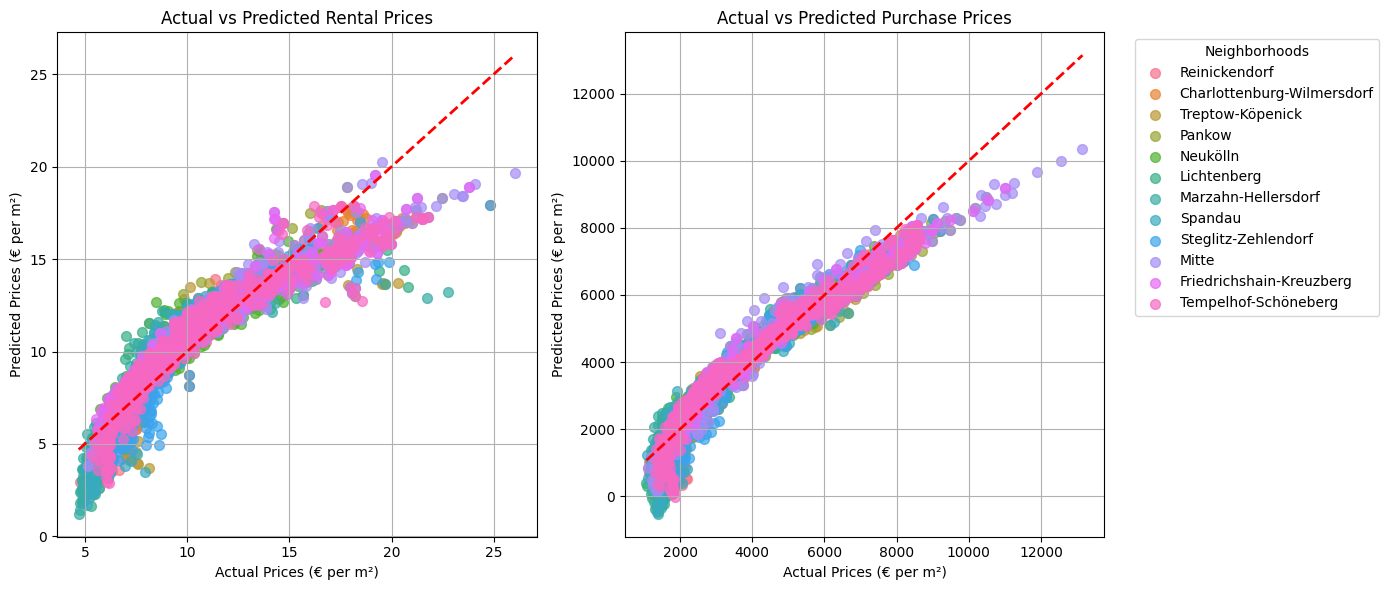

In [58]:
# Predictions for full dataset
y_pred_full_rent = regressor_rent.predict(X_rent)
y_pred_full_purch = regressor_purch.predict(X_purch)

# Add predictions to original datasets
merged_gdf_rent['predicted_price'] = y_pred_full_rent
merged_gdf_purch['predicted_price'] = y_pred_full_purch

# Set up the plot
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Colors for different neighborhoods
colors = sns.color_palette("husl", len(merged_gdf_rent['neighborhood'].unique()))

# --------- Rental Prices Plot ---------
for i, neighborhood in enumerate(merged_gdf_rent['neighborhood'].unique()):
    neighborhood_data = merged_gdf_rent[merged_gdf_rent['neighborhood'] == neighborhood]
    axes[0].scatter(neighborhood_data['price_qm'], neighborhood_data['predicted_price'],
                    label=neighborhood, alpha=0.7, s=50, color=colors[i])

axes[0].plot([y_rent.min(), y_rent.max()], [y_rent.min(), y_rent.max()],
             color='red', linestyle='--', lw=2)

axes[0].set_xlabel('Actual Prices (€ per m²)')
axes[0].set_ylabel('Predicted Prices (€ per m²)')
axes[0].set_title('Actual vs Predicted Rental Prices')
axes[0].grid(True)

# --------- Purchase Prices Plot ---------
for i, neighborhood in enumerate(merged_gdf_purch['neighborhood'].unique()):
    neighborhood_data = merged_gdf_purch[merged_gdf_purch['neighborhood'] == neighborhood]
    axes[1].scatter(neighborhood_data['price_qm'], neighborhood_data['predicted_price'],
                    label=neighborhood, alpha=0.7, s=50, color=colors[i])

axes[1].plot([y_purch.min(), y_purch.max()], [y_purch.min(), y_purch.max()],
             color='red', linestyle='--', lw=2)

axes[1].set_xlabel('Actual Prices (€ per m²)')
axes[1].set_ylabel('Predicted Prices (€ per m²)')
axes[1].set_title('Actual vs Predicted Purchase Prices')
axes[1].grid(True)

axes[1].legend(title='Neighborhoods', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()


In [59]:
# Compute residuals
merged_gdf_rent['residuals'] = merged_gdf_rent['price_qm'] - merged_gdf_rent['predicted_price']
merged_gdf_purch['residuals'] = merged_gdf_purch['price_qm'] - merged_gdf_purch['predicted_price']


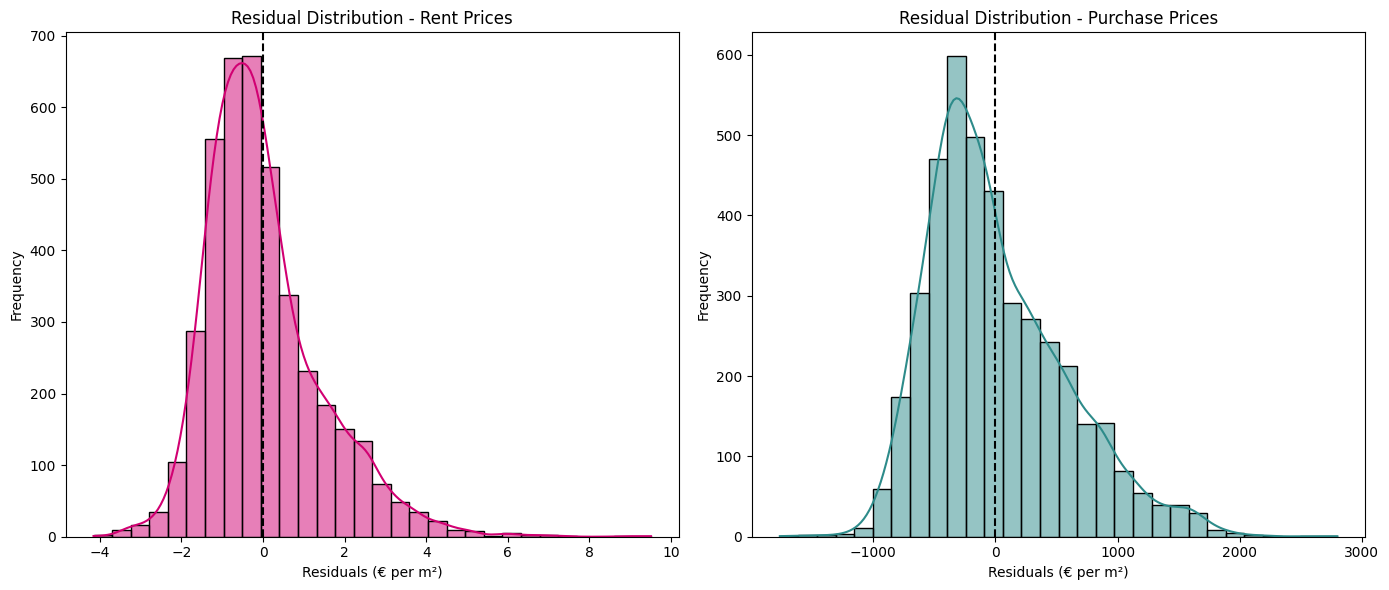

In [60]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# --------- Rental Residuals Histogram ---------
sns.histplot(merged_gdf_rent['residuals'], bins=30, kde=True, ax=axes[0], color='#D10072')
axes[0].axvline(0, color='black', linestyle='dashed')
axes[0].set_title("Residual Distribution - Rent Prices")
axes[0].set_xlabel("Residuals (€ per m²)")
axes[0].set_ylabel("Frequency")

# --------- Purchase Residuals Histogram ---------
sns.histplot(merged_gdf_purch['residuals'], bins=30, kde=True, ax=axes[1], color='#2D8B8A')
axes[1].axvline(0, color='black', linestyle='dashed')
axes[1].set_title("Residual Distribution - Purchase Prices")
axes[1].set_xlabel("Residuals (€ per m²)")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()


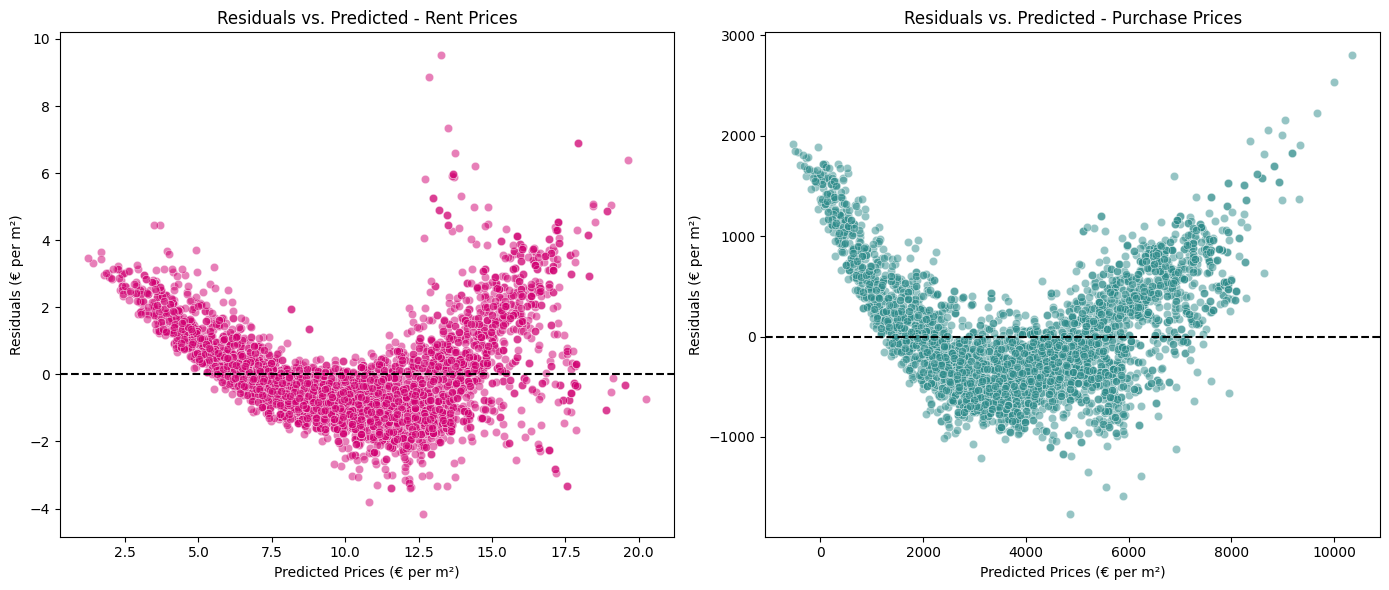

In [61]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# --------- Residuals vs. Predicted for Rent ---------
sns.scatterplot(x=merged_gdf_rent['predicted_price'], y=merged_gdf_rent['residuals'], alpha=0.5, ax=axes[0], color='#D10072')
axes[0].axhline(0, color='black', linestyle='dashed')
axes[0].set_title("Residuals vs. Predicted - Rent Prices")
axes[0].set_xlabel("Predicted Prices (€ per m²)")
axes[0].set_ylabel("Residuals (€ per m²)")

# --------- Residuals vs. Predicted for Purchase ---------
sns.scatterplot(x=merged_gdf_purch['predicted_price'], y=merged_gdf_purch['residuals'], alpha=0.5, ax=axes[1], color='#2D8B8A')
axes[1].axhline(0, color='black', linestyle='dashed')
axes[1].set_title("Residuals vs. Predicted - Purchase Prices")
axes[1].set_xlabel("Predicted Prices (€ per m²)")
axes[1].set_ylabel("Residuals (€ per m²)")

plt.tight_layout()
plt.show()
